### Modern Portfolio Theory  

 **Modern Portfolio Theory (MPT)** describes how risk-averse investors can construct portfolios that maximize expected returns for a given level of market risk. Rather than evaluating an investment’s risk and return independently, MPT focuses on how each asset impacts the portfolio’s overall performance. It emphasizes the importance of diversification.
 *Not putting all your eggs in one basket.*  

In this project, we calculate the **Annual Mean Return** and **Annual Standard Deviation (Volatility)** by generating multiple portfolios with random stock weight allocations. From these simulations, we identify the portfolio with the **highest Sharpe Ratio** (Return ÷ Volatility) and the **lowest volatility**, representing the most efficient trade-off between risk and reward.


Here I will use 5 NSE stocks - INFOSYS, SUNPHARMA, ITC, COALINDIA, SBIN - with 3 years of daily
adjusted closing prices (Nov 2023 – Nov 2026), downloaded directly from Yahoo Finance using yfinance.

In [1]:
#importing necessary libraries
!pip install yfinance -q
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

Downloading adjusted closing prices and storing them in a dataframe called ‘CP_df’.

In [2]:
#downloading 3 years of daily adjusted closing prices from Yahoo Finance
tickers = ['INFY.NS', 'SUNPHARMA.NS', 'ITC.NS', 'COALINDIA.NS', 'SBIN.NS']  # .NS = NSE listing
CP_df = yf.download(tickers, period='3y', auto_adjust=True)['Close'].dropna()
CP_df.columns = [c.replace('.NS', '') for c in CP_df.columns]
CP_df

[*********************100%***********************]  5 of 5 completed


,COALINDIA,INFY,ITC,SBIN,SUNPHARMA
Date,,,,,
2023-11-09,255.453064,1238.565308,372.868958,547.741455,1144.595459
2023-11-10,255.334610,1233.204834,374.714386,548.830627,1147.660889
2023-11-13,275.822968,1237.438965,374.242310,550.582642,1146.152466
2023-11-15,276.809906,1270.727539,379.349487,553.755493,1149.169312
2023-11-16,273.020142,1301.718628,376.516968,553.708069,1157.586914
...,...,...,...,...,...
2026-11-03,397.750000,1148.099976,273.899994,970.250000,1769.900024
2026-11-04,399.649994,1128.199951,280.000000,979.000000,1773.400024
2026-11-05,394.299988,1167.400024,278.850006,1006.400024,1829.000000


Now all the pre- processing is done. Now lets calculate the Portfolio Return and Volatility.<br />
<br />
First I will calculate with equal weight to each stock.

In [3]:
daily_return = np.log(CP_df.pct_change() + 1).dropna()
#Here I am calculating log daily returns and removing the first empty column of each stock

#Now calculating mean of those daily return
daily_return_mean = np.array(daily_return.mean())

#Now assigning weights
#Since there are five stocks so each will have a weight of 0.2 (1/5)
weights = np.array([0.2,0.2,0.2,0.2,0.2])

![](https://www.wallstreetmojo.com/wp-content/uploads/2019/04/Portfolio-Return-Formula.jpg)

### Here "w" is the weight and "r" is the return.

![](https://cdn.corporatefinanceinstitute.com/assets/portfolio-variance-formula-1024x84.png)

### Here "Sigma" is the standard deviation and "Cov" is the covariance.

In [4]:
#Calculating Portfolio Return
Port_return = np.sum(weights * daily_return_mean)

print('The Annual Return of Portfolio is {}%'.format((Port_return * 252)*100))
#Here 252 is multiplied for annual calculation i.e. 252 trading days in a year

The Annual Return of Portfolio is 8.477741215312026%


In [5]:
#Calculating Portfolio Volatility
cov = daily_return.cov()
Port_Vol = np.sqrt(np.dot(weights.T,np.dot(cov,weights)))

print('The Annual Volatility of Portfolio is {}%'.format((Port_Vol * np.sqrt(252))*100))

The Annual Volatility of Portfolio is 13.835115330310652%


So far we have seen the Annual Return and Annual Volatility  of Portfolio if equal weight given to each stock.<br />
<br />
Now comes the random generation of portfolio i.e. **Monte Carlo Simulation**.

In [6]:
#Declare the number of Portfolio to be generated
num_portfolio = 30000

# makes results reproducible
np.random.seed(42)

#creating a empty list for storing returns,volatility,sharpe_ratio(return/volatility) and weightage of each stock in portfolio
results = np.zeros((3 + len(daily_return.columns),num_portfolio))



#Monte Carlo Simulation
for i in range(num_portfolio):

    weight = np.random.rand(len(daily_return.columns)) #Declaring random weights
    weight = weight/np.sum(weight) #So that sum of all weight will be equal to 1

    p_annual_return = np.sum(weight * daily_return_mean) * 252 #Annual Return
    p_annual_volatility = np.sqrt(np.dot(weight.T,np.dot(cov,weight))) * np.sqrt(252) #Annual Volatility

    #Storing the values in results list
    results[0,i] = p_annual_return
    results[1,i] = p_annual_volatility
    results[2,i] = results[0,i]/results[1,i]

    for j in range(len(weight)):
        results[j+3,i] =  weight[j]



#Making a dataframe for results list of all generated Portfolio
cols = ['Ann_Ret','Ann_Vol','Sharpe_Ratio']
for num in range(len(list(daily_return.columns))):
    cols.append(list(daily_return.columns)[num])


result_df = pd.DataFrame(results.T,columns=cols)



In [7]:
#Visulising the result dataframe
result_df

,Ann_Ret,Ann_Vol,Sharpe_Ratio,COALINDIA,INFY,ITC,SBIN,SUNPHARMA
0,0.042908,0.148825,0.288312,0.133197,0.338101,0.260318,0.212900,0.055485
1,0.080162,0.136935,0.585406,0.065285,0.024308,0.362501,0.251571,0.296334
2,-0.011087,0.158702,-0.069860,0.009284,0.437468,0.375464,0.095773,0.082010
3,0.065809,0.136318,0.482756,0.105673,0.175297,0.302353,0.248877,0.167800
4,0.118733,0.150244,0.790269,0.327909,0.074759,0.156568,0.196343,0.244421
...,...,...,...,...,...,...,...,...
29995,0.081216,0.143893,0.564422,0.139488,0.335587,0.108661,0.137721,0.278544
29996,0.071701,0.133133,0.538566,0.074788,0.206385,0.254054,0.210866,0.253906
29997,0.078672,0.137374,0.572685,0.202406,0.193059,0.224510,0.183672,0.196354
29998,0.064446,0.139043,0.463496,0.257802,0.064768,0.347968,0.077725,0.251737


In [8]:
#locating
#Portfolio 1 - Sharpe ratio is the highest (Return/Volatility)
#Portfolio 2 - Volatility is the lowest


#Portfolio 1
max_sharpe_ratio = result_df.iloc[result_df['Sharpe_Ratio'].idxmax()]

#Portfolio 2
volatility_lowest = result_df.iloc[result_df['Ann_Vol'].idxmin()]

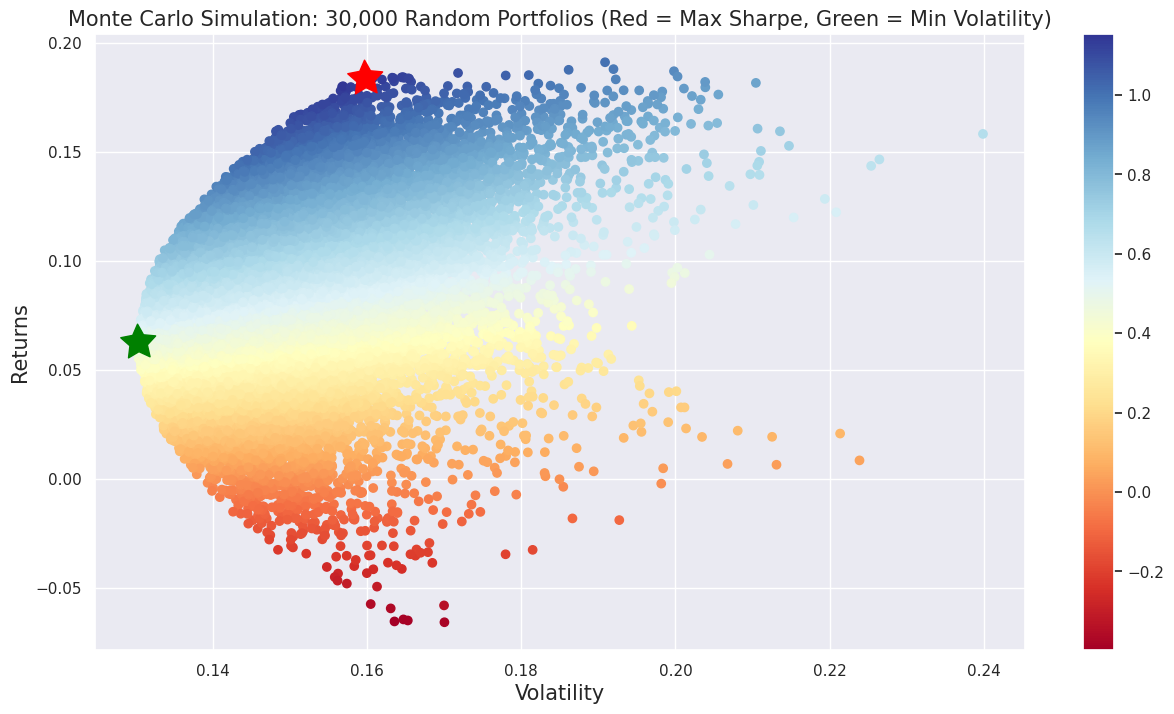

In [9]:
#Plotting the simulation
plt.figure(figsize=(15,8))
plt.scatter(result_df['Ann_Vol'],result_df['Ann_Ret'],c =result_df['Sharpe_Ratio'],cmap='RdYlBu')
plt.colorbar()

plt.scatter(max_sharpe_ratio.iloc[1], max_sharpe_ratio.iloc[0], marker=(5,1,3), color='red', s=700) #Red - Portfolio 1
plt.scatter(volatility_lowest.iloc[1], volatility_lowest.iloc[0], marker=(5,1,3), color='green', s=700)#Green - Portfolio 2


plt.xlabel('Volatility',fontsize = 15)
plt.ylabel('Returns',fontsize = 15)
plt.title('Monte Carlo Simulation: 30,000 Random Portfolios (Red = Max Sharpe, Green = Min Volatility)', fontsize=15)
plt.savefig('efficient_frontier.png', dpi=150, bbox_inches='tight')
plt.show()

   # Conclusion:

In [12]:
print('The Portfolio with the maximum Sharpe Ratio is:')
print('All values in percentage')
print(round(max_sharpe_ratio * 100,2))

The Portfolio with the maximum Sharpe Ratio is:
All values in percentage
Ann_Ret          18.43
Ann_Vol          15.98
Sharpe_Ratio    115.33
COALINDIA         3.91
INFY              0.07
ITC               2.27
SBIN             38.76
SUNPHARMA        54.99
Name: 28705, dtype: float64


In [11]:
print('The Portfolio with least Volatility is:')
print('All values in percentage')
print(round(volatility_lowest * 100,2))

The Portfolio with least Volatility is:
All values in percentage
Ann_Ret          6.28
Ann_Vol         13.02
Sharpe_Ratio    48.20
COALINDIA        8.12
INFY            14.84
ITC             31.44
SBIN            12.70
SUNPHARMA       32.91
Name: 29026, dtype: float64


The equal-weight portfolio returned 8.5% at 13.8% volatility (Sharpe 0.61).
The max-Sharpe portfolio (55% Sun Pharma, 39% SBI) returned 18.4% at 16.0% volatility
(Sharpe 1.15), nearly doubling the return-to-risk ratio. The minimum-volatility portfolio
cut risk to 13.0% but returned only 6.3%.

Note: Sharpe ratio here = return / volatility, and results are
historical (Nov 2023 – Nov 2026), not a forecast.